## differential-analysis-notebook
11.5.25

In [55]:
import pandas as pd
import numpy as np 
from scipy import stats
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

# plotting templates
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

#### Configs

In [56]:
unimputed_path="../quant-reports/CalCurves-unimputed-report.csv"
cortado_path="../quant-reports/CalCurves-cortado-report.csv"
nettle_path="../quant-reports/CalCurves-nettle-report.csv"

pval_thresh=0.05
q_thresh_a100=0.1

#### Functions 

In [57]:
def average_replicates(report):
    """
    Just like previous, except that here we take the average across the three
    replicates instead of concatting. Also calcualtes the standard deviation across
    the three replicates and sets the averaged quant to NaN if it is greater than
    some specified threshold. 
    
    Parameters
    ----------
    report : `pandas.DataFrame`, 
        The Skyline quants report 
    std_thresh : float, 
        The threshold, in standard deviations, to use for determining whether or
        not to retain an averaged quant value 
        
    Returns
    ----------
    report_comb : `pandas.DataFrame`, 
    """
    colnames = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N"]
    comb_arr = []
    
    for i in range(0, report.shape[1], 3):
        colname1 = list(report.columns)[i]
        colname2 = list(report.columns)[i+1]
        colname3 = list(report.columns)[i+2]
    
        col1 = np.array(report[colname1])
        col2 = np.array(report[colname2])
        col3 = np.array(report[colname3])

        ave = np.nanmean([col1, col2, col3], axis=0)
        comb_arr.append(list(ave))
    
    report_comb = pd.DataFrame(comb_arr).T
    report_comb.columns = colnames 
 
    return report_comb

#### Read in and pre-process the quants reports 

In [58]:
to_drop = ["Protein Name", "Peptide Modified Sequence", "Precursor Charge"]
           
# Read in the three Skyline report csvs
unimputed_df = pd.read_csv(unimputed_path)
unimputed_df.index = unimputed_df["Peptide Modified Sequence"]
unimputed_df = unimputed_df.drop(columns=to_drop)

cortado_df = pd.read_csv(cortado_path)
cortado_df.index = cortado_df["Peptide Modified Sequence"]
cortado_df = cortado_df.drop(columns=to_drop)

nettle_df = pd.read_csv(nettle_path)
nettle_df.index = nettle_df["Peptide Modified Sequence"]
nettle_df = nettle_df.drop(columns=["Protein Name", "Peptide Modified Sequence"])

print(unimputed_df.shape)
print(cortado_df.shape)
print(nettle_df.shape)

(42093, 42)
(42011, 42)
(37362, 42)


#### Drop duplicates and sort 

In [59]:
# DROP DUPLICATES
unimputed_df = unimputed_df[~unimputed_df.index.duplicated(keep="first")]
cortado_df = cortado_df[~cortado_df.index.duplicated(keep="first")]
nettle_df = nettle_df[~nettle_df.index.duplicated(keep="first")]

# SORT 
unimputed_df = unimputed_df.loc[sorted(unimputed_df.index)]
cortado_df = cortado_df.loc[sorted(cortado_df.index)]
nettle_df = nettle_df.loc[sorted(nettle_df.index)]

print(unimputed_df.shape)
print(cortado_df.shape)
print(nettle_df.shape)

(33660, 42)
(33612, 42)
(33612, 42)


In [60]:
np.count_nonzero(np.isnan(unimputed_df)) / unimputed_df.size

0.7164728517669694

#### Handle the missing values 

In [61]:
unimputed_df[unimputed_df == 0.0] = np.nan
unimputed_df[np.isinf(unimputed_df)] = np.nan

cortado_df[cortado_df == 0.0] = np.nan
cortado_df[np.isinf(cortado_df)] = np.nan

nettle_df[nettle_df == 0.0] = np.nan
nettle_df[np.isinf(nettle_df)] = np.nan

#### Subset to only the shared peptides 

In [62]:
inter = set.intersection(set(unimputed_df.index), set(cortado_df.index), set(nettle_df.index))

unimputed_df = unimputed_df.loc[list(inter)]
cortado_df = cortado_df.loc[list(inter)]
nettle_df = nettle_df.loc[list(inter)]

print(unimputed_df.shape)
print(cortado_df.shape)
print(nettle_df.shape)

(33612, 42)
(33612, 42)
(33612, 42)


#### Log transform 

In [63]:
unimputed_df = np.log(unimputed_df)
cortado_df = np.log(cortado_df)
nettle_df = np.log(nettle_df)

#### Ensemble Nettle and Cortado 

In [64]:
nettle_arr = np.array(nettle_df)
cortado_arr = np.array(cortado_df)

mean_arr = np.average([nettle_arr, cortado_arr], weights=[0.5, 0.5], axis=0)
ensembled_df = pd.DataFrame(mean_arr, index=nettle_df.index, columns=nettle_df.columns)
#ensembled_df[np.isnan(ensembled_df)] = nettle_df

print(ensembled_df.shape)

(33612, 42)


#### Subset 
For the sake of testing. 

In [65]:
unimputed_df = unimputed_df[:10000]
nettle_df = nettle_df[:10000]
cortado_df = cortado_df[:10000]
ensembled_df = ensembled_df[:10000]

#### Differential expression testing -- Unimputed

In [66]:
big_list = []
for i in range(0, unimputed_df.shape[1], 3):
    df1 = unimputed_df.iloc[:, 0:3]
    df2 = unimputed_df.iloc[:, i:i+3]

    pvals = []
    for i in tqdm(range(0, df1.shape[0])):
        stat, pval = stats.ttest_ind(np.array(df1.iloc[i]), np.array(df2.iloc[i]), nan_policy="omit")
        pvals.append(np.float32(pval))

    big_list.append(pvals)

unimputed_pvals_df = pd.DataFrame(big_list).T
unimputed_pvals_df[unimputed_pvals_df == 0.0] = np.nan
unimputed_pvals_df[unimputed_pvals_df == 1.0] = np.nan

  0%|                                      | 0/10000 [00:00<?, ?it/s]/net/noble/vol2/home/lincolnh/miniconda3/envs/deep-impute/lib/python3.9/site-packages/scipy/stats/_stats_py.py:6951: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df
100%|████████████████████████| 10000/10000 [00:09<00:00, 1023.13it/s]


#### Differential expression testing -- Nettle 

In [67]:
big_list = []
for i in range(0, ensembled_df.shape[1], 3):
    df1 = ensembled_df.iloc[:, 0:3]
    df2 = ensembled_df.iloc[:, i:i+3]

    pvals = []
    for i in tqdm(range(0, df1.shape[0])):
        stat, pval = stats.ttest_ind(np.array(df1.iloc[i]), np.array(df2.iloc[i]), nan_policy="omit")
        pvals.append(np.float32(pval))

    big_list.append(pvals)

ensembled_pvals_df = pd.DataFrame(big_list).T
ensembled_pvals_df[ensembled_pvals_df == 0.0] = np.nan
ensembled_pvals_df[ensembled_pvals_df == 1.0] = np.nan

  0%|                                      | 0/10000 [00:00<?, ?it/s]/net/noble/vol2/home/lincolnh/miniconda3/envs/deep-impute/lib/python3.9/site-packages/scipy/stats/_stats_py.py:6951: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df
100%|█████████████████████████| 10000/10000 [00:18<00:00, 551.33it/s]


#### BH correction -- Unimputed 

In [68]:
unimputed_pvals_df[np.isnan(unimputed_pvals_df)] = 1.0
unimputed_pvals_adj_df = unimputed_pvals_df.copy()

for i in range(0, unimputed_pvals_df.shape[1]):
    curr = unimputed_pvals_df.iloc[:,i]
    curr = curr.sort_values(ascending=True)
    pvals_adj_curr = stats.false_discovery_control(curr, method="bh")
    unimputed_pvals_adj_df.iloc[:,i] = pvals_adj_curr

#### BH correction -- Nettle 

In [69]:
ensembled_pvals_df[np.isnan(ensembled_pvals_df)] = 1.0
ensembled_pvals_adj_df = ensembled_pvals_df.copy()

for i in range(0, ensembled_pvals_df.shape[1]):
    curr = ensembled_pvals_df.iloc[:,i]
    curr = curr.sort_values(ascending=True)
    pvals_adj_curr = stats.false_discovery_control(curr, method="bh")
    ensembled_pvals_adj_df.iloc[:,i] = pvals_adj_curr

#### Count the number of significant DE peptides 

In [70]:
de_count_unimputed = np.count_nonzero(unimputed_pvals_adj_df < pval_thresh, axis=0)
de_count_ensembled = np.count_nonzero(ensembled_pvals_adj_df < pval_thresh, axis=0)

# Make a dataframe for plotting
de_plotter = pd.DataFrame(columns=["Condition", "Unimputed", "Nettle"])
de_plotter["Condition"] = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N"]
de_plotter["Unimputed"] = de_count_unimputed
de_plotter["Nettle"] = de_count_ensembled

# Zoom in on just the C-I columns that we want to include in our plot
de_plotter = de_plotter[2:9]
de_plotter = de_plotter.drop(index=5)
de_plotter = de_plotter.drop(columns="Condition")
de_plotter["Frac"] = [50, 30, 10, 5, 3, 1]
de_plotter_melt = de_plotter.melt(id_vars="Frac")

#### Define the custom color map 

In [71]:
cmap_cust = list(plt.cm.tab10.colors)
cmap_cust[0] = cmap_cust[7] # set index 0 to gray
cmap_cust[1] = cmap_cust[4] # set index 1 to purple 
cmap_cust = tuple(cmap_cust)

#### Make bar plots 

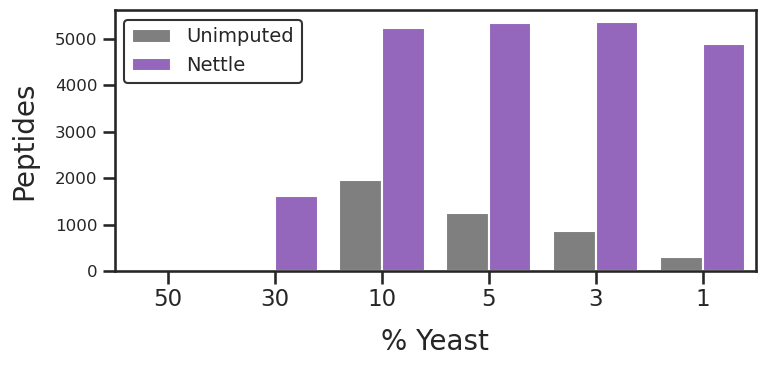

In [72]:
fig, ax = plt.subplots(figsize=(8,4))

sns.barplot(
    data=de_plotter_melt,
    x="Frac", y="value",
    hue="variable",
    palette=cmap_cust,
    saturation=1.0,
    order=[50, 30, 10, 5, 3, 1],
)

plt.xlabel("% Yeast", labelpad=12, size=20)
plt.ylabel("Peptides", labelpad=12, size=20)

#ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=12)

plt.legend(edgecolor="black", prop={"size":14}, loc="upper left")

plt.tight_layout()
#plt.savefig("../figures/calcurves-n-differential.png", bbox_inches="tight", dpi=350)
#plt.savefig("../figures/calcurves-n-differential.pdf", bbox_inches="tight")

#### Get some stats for the additional DE peptides 

In [73]:
np.mean(de_plotter["Nettle"] - de_plotter["Unimputed"])

3013.6666666666665

---
## Plot number of quantitative peptides at each dilution 
The end goal is to create a single panel that combines # of quant peptides with # of differential peptides, for every sample in the MMCC experiment. 

#### Get the averages across the three replicate conditions 

In [74]:
unimputed_df_mean = average_replicates(unimputed_df)
cortado_df_mean = average_replicates(cortado_df)
nettle_df_mean = average_replicates(nettle_df)

print(unimputed_df_mean.shape)
print(nettle_df_mean.shape)
print(cortado_df_mean.shape)

/tmp/ipykernel_1160700/1118163785.py:32: RuntimeWarning: Mean of empty slice
  ave = np.nanmean([col1, col2, col3], axis=0)
/tmp/ipykernel_1160700/1118163785.py:32: RuntimeWarning: Mean of empty slice
  ave = np.nanmean([col1, col2, col3], axis=0)
/tmp/ipykernel_1160700/1118163785.py:32: RuntimeWarning: Mean of empty slice
  ave = np.nanmean([col1, col2, col3], axis=0)


(10000, 14)
(10000, 14)
(10000, 14)


#### (Re)ensembled Nettle and Cortado 

In [75]:
nettle_arr = np.array(nettle_df_mean)
cortado_arr = np.array(cortado_df_mean)

mean_arr = np.average([nettle_arr, cortado_arr], weights=[0.5, 0.5], axis=0)
ensembled_df_mean = pd.DataFrame(mean_arr, index=nettle_df_mean.index, columns=nettle_df_mean.columns)
#ensembled_df[np.isnan(ensembled_df)] = nettle_df

print(ensembled_df_mean.shape)

(10000, 14)


#### Remove peptides with low abundances in the A100 condition 

In [76]:
# Get an index of the values that we want to set to NaN
test_df = np.log(unimputed_df_mean)
a_arr = np.array(test_df["A"])
q_lower = np.nanquantile(a_arr, q=q_thresh_a100)
a_arr[a_arr <= q_lower] = np.nan
a_arr = np.isnan(a_arr)

# Set to NaN
unimputed_df_mean.loc[a_arr, :] = np.nan
cortado_df_mean.loc[a_arr, :] = np.nan
nettle_df_mean.loc[a_arr, :] = np.nan
ensembled_df_mean.loc[a_arr, :] = np.nan

/net/noble/vol2/home/lincolnh/miniconda3/envs/deep-impute/lib/python3.9/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


#### Get the number of quant peptides for unimputed vs Nettle

In [77]:
unimputed_pvs = np.count_nonzero(~np.isnan(unimputed_df_mean), axis=0)
ensembled_pvs = np.count_nonzero(~np.isnan(ensembled_df_mean), axis=0)

npeptides_plotter = pd.DataFrame(columns=["Unimputed", "Nettle", "frac"])

npeptides_plotter["Unimputed"] = unimputed_pvs
npeptides_plotter["Nettle"] = ensembled_pvs

npeptides_plotter = npeptides_plotter[2:9]
npeptides_plotter = npeptides_plotter.drop(index=5)

npeptides_plotter["frac"] = [50, 30, 10, 5, 3, 1]

npeptides_plotter_melt = npeptides_plotter.melt(id_vars="frac")

#### Standard bar plot 

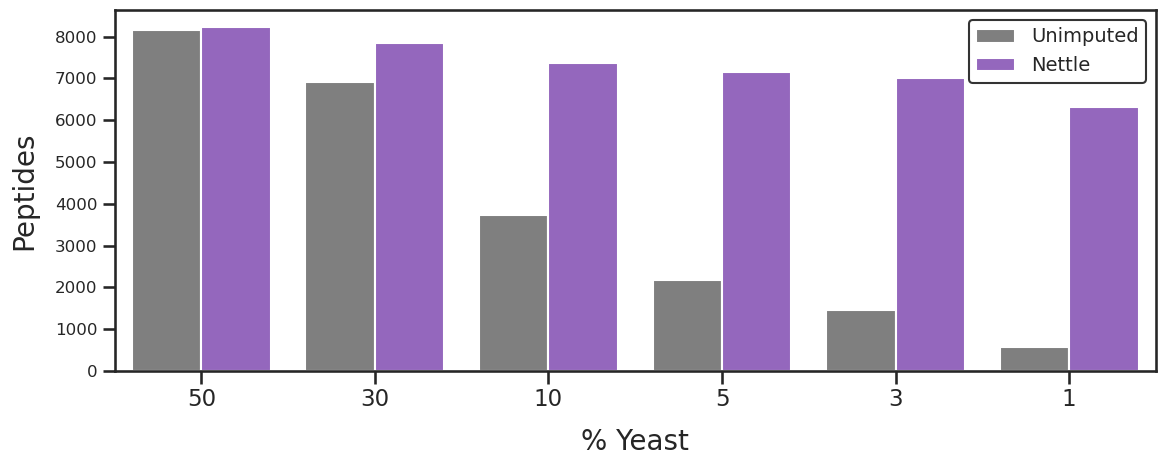

In [78]:
fig, ax = plt.subplots(figsize=(12,5))

sns.barplot(
    data=npeptides_plotter_melt, 
    x="frac", y="value", 
    hue="variable",
    palette=cmap_cust, 
    saturation=1.0,
    order=[50, 30, 10, 5, 3, 1],
)

plt.xlabel("% Yeast", labelpad=12, size=20)
plt.ylabel("Peptides", labelpad=12, size=20)

#ax.set_xticklabels(percent_yeast)
#ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=12)

#leg = plt.legend(edgecolor="black", prop={"size":12}, bbox_to_anchor=(1.01, 1.0))
plt.legend(edgecolor="black", prop={"size":14}, loc="upper right")
#leg.remove()

plt.tight_layout()

#### Change up the column names 

In [129]:
npeptides_plotter.columns = ["Unimputed - Total", "Nettle - Total", "frac"]
npeptides_plotter_melt = npeptides_plotter.melt(id_vars="frac")

de_plotter.columns = ["Unimputed - Differential", "Nettle - Differential", "frac"]
de_plotter_melt = de_plotter.melt(id_vars="frac")

#### A second custom colormap 

In [130]:
alt_purple=(0.8274509803921568, 0.6392156862745098, 1)
alt_gray=(0.7607843137254902, 0.7607843137254902, 0.7607843137254902)

cmap_cust1 = list(plt.cm.tab10.colors)
cmap_cust1[0] = alt_gray
cmap_cust1[1] = alt_purple
cmap_cust1 = tuple(cmap_cust1)

#### Stacked bar plot? 

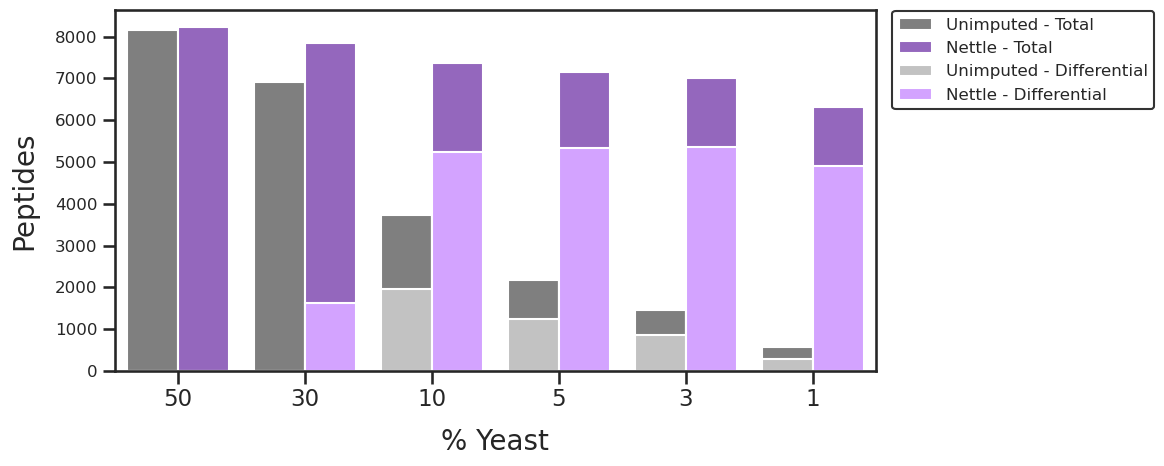

In [135]:
fig, ax = plt.subplots(figsize=(12,5))

# The n total peptides bar 
bar1 = sns.barplot(
    data=npeptides_plotter_melt, 
    x="frac", y="value", 
    hue="variable",
    palette=cmap_cust, 
    saturation=1.0,
    order=[50, 30, 10, 5, 3, 1],
)
# The n DE peptides bar
bar2 = sns.barplot(
    data=de_plotter_melt,
    x="frac", y="value",
    hue="variable",
    palette=cmap_cust1,
    saturation=1.0,
    order=[50, 30, 10, 5, 3, 1],
)

plt.xlabel("% Yeast", labelpad=12, size=20)
plt.ylabel("Peptides", labelpad=12, size=20)

ax.tick_params(axis='y', which='major', labelsize=12)

plt.legend(edgecolor="black", prop={"size":12}, bbox_to_anchor=(1.01, 1.02))

plt.tight_layout()
plt.savefig("../figures/DE-stacked-bar.png", dpi=350, bbox_inches="tight")